In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv('data/train_FD004_with_umap.csv')
umap_cols = ['umap_1', 'umap_2', 'umap_3']
sensor_cols = [c for c in df.columns if c.startswith('s_')]
print(df.shape)
df[umap_cols + ['RUL', 'op_cond']].describe()

(61249, 21)


,umap_1,umap_2,umap_3,RUL,op_cond
count,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000
mean,8.391954,6.770468,0.033297,92.985192,2.245539
std,3.137352,2.878388,0.587404,40.665112,1.787114
min,-1.771856,-0.386743,-1.698176,0.000000,0.000000
25%,7.510857,4.860001,-0.381672,61.000000,0.000000
50%,9.297248,7.002068,0.035837,122.000000,2.000000
75%,10.460812,8.597576,0.479330,125.000000,4.000000
max,12.490495,14.180165,2.055191,125.000000,5.000000


In [3]:
results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(df[umap_cols])
    sil = silhouette_score(df[umap_cols], labels, sample_size=5000, random_state=42)
    results.append({'k': k, 'inertia': km.inertia_, 'silhouette': sil})
    print(f'k={k}: inertia={km.inertia_:.1f}, silhouette={sil:.3f}')

results_df = pd.DataFrame(results)

k=2: inertia=575108.3, silhouette=0.480
k=3: inertia=273150.3, silhouette=0.533
k=4: inertia=198594.0, silhouette=0.480
k=5: inertia=140584.2, silhouette=0.449
k=6: inertia=105289.5, silhouette=0.452
k=7: inertia=84159.4, silhouette=0.442
k=8: inertia=73157.7, silhouette=0.430


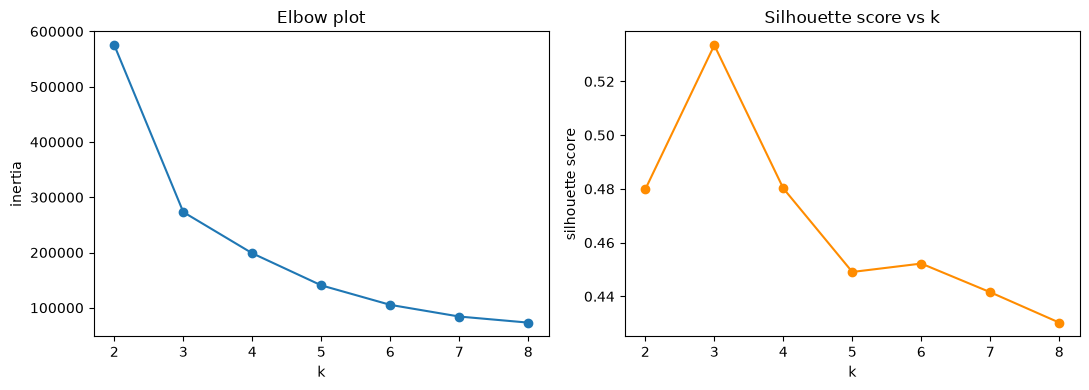

Best k by silhouette score: 3


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(results_df['k'], results_df['inertia'], marker='o')
axes[0].set_xlabel('k'); axes[0].set_ylabel('inertia'); axes[0].set_title('Elbow plot')

axes[1].plot(results_df['k'], results_df['silhouette'], marker='o', color='darkorange')
axes[1].set_xlabel('k'); axes[1].set_ylabel('silhouette score'); axes[1].set_title('Silhouette score vs k')
plt.tight_layout()
plt.savefig('kmeans_k_selection.png', dpi=120)
plt.show()

best_k = int(results_df.loc[results_df['silhouette'].idxmax(), 'k'])
print(f'Best k by silhouette score: {best_k}')

In [6]:
final_km = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df['cluster'] = final_km.fit_predict(df[umap_cols])
print(df['cluster'].value_counts().sort_index())

cluster
0    25234
1     9316
2    26699
Name: count, dtype: int64


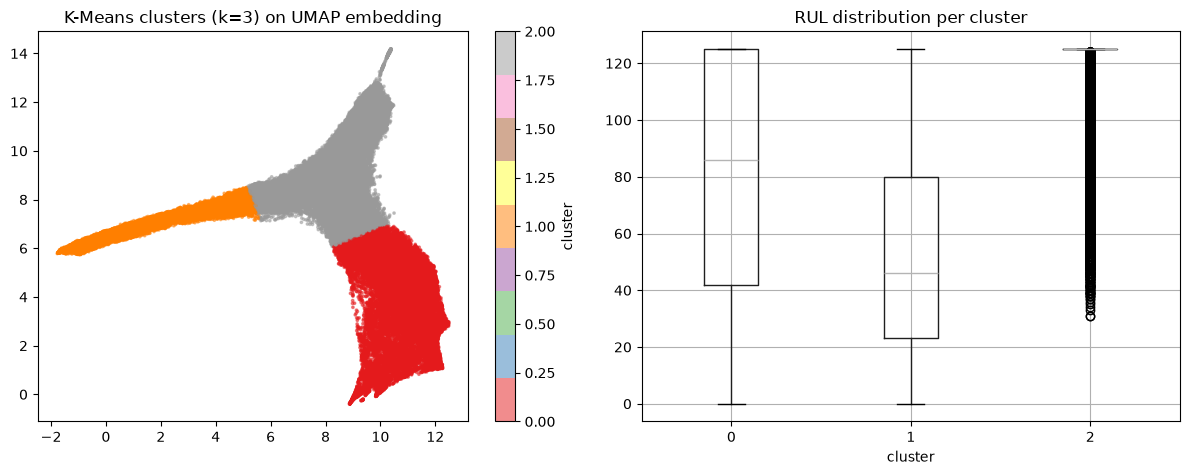

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc = axes[0].scatter(df['umap_1'], df['umap_2'], c=df['cluster'], cmap='Set1', s=3, alpha=0.5)
axes[0].set_title(f'K-Means clusters (k={best_k}) on UMAP embedding')
plt.colorbar(sc, ax=axes[0], label='cluster')

df.boxplot(column='RUL', by='cluster', ax=axes[1])
axes[1].set_title('RUL distribution per cluster')
plt.suptitle('')
plt.tight_layout()
plt.savefig('kmeans_cluster_interpretation.png', dpi=120)
plt.show()

In [8]:
# Sensor fingerprint: mean normalized sensor value per cluster
cluster_profile = df.groupby('cluster')[sensor_cols].mean()
print('Mean (normalized) sensor value per cluster:')
cluster_profile.T.round(2)

Mean (normalized) sensor value per cluster:


cluster,0,1,2
s_2,0.68,0.18,-0.70
s_3,0.54,0.63,-0.73
s_4,0.66,0.51,-0.80
s_7,-0.43,1.88,-0.25
s_8,0.05,1.15,-0.45
s_9,0.04,1.22,-0.46
s_11,0.65,0.63,-0.83
s_12,-0.42,1.90,-0.27
s_13,0.05,1.15,-0.45
s_14,-0.09,1.28,-0.36


In [9]:
# Which sensors differ most between clusters? (range across cluster means, descending)
sensor_spread = (cluster_profile.max() - cluster_profile.min()).sort_values(ascending=False)
print('Sensors that differ most between clusters:')
print(sensor_spread.head(8))

Sensors that differ most between clusters:
s_15    2.488763
s_12    2.319825
s_7     2.307870
s_21    1.833101
s_20    1.826527
s_9     1.682496
s_14    1.637866
s_13    1.601305
dtype: float64


In [10]:
df.to_csv('data/train_FD004_with_clusters.csv', index=False)
print('Saved. Shape:', df.shape)

Saved. Shape: (61249, 22)
